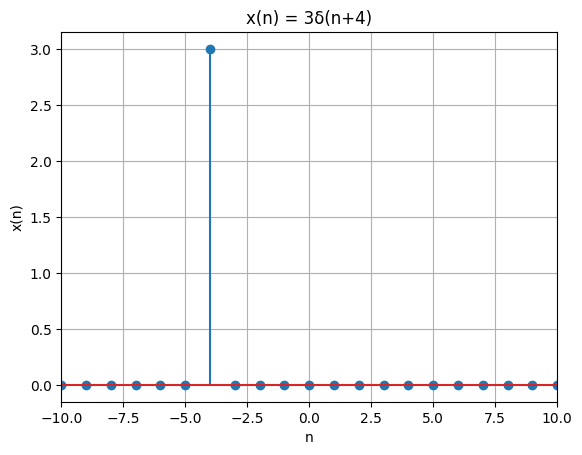

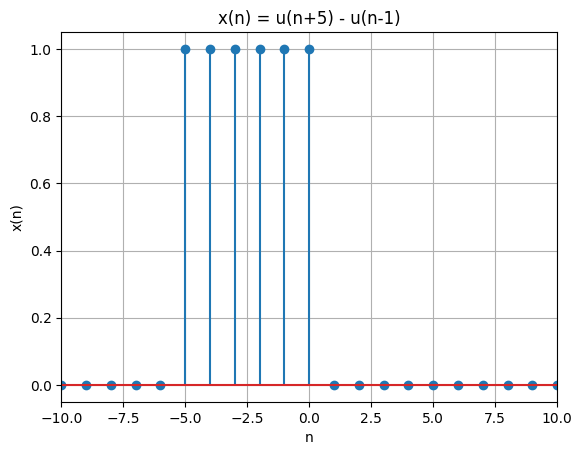

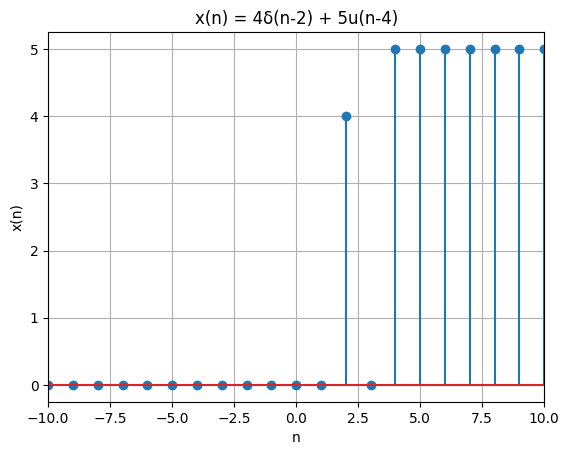

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Define delta and unit step as lambdas (same as labs)
delta = lambda n: n==0
unit = lambda n: n>=0

n = range(-10, 11, 1)  # interval [-10, 10]

# ── a) x(n) = 3δ(n+4) ──────────────────────────────────────────
ya = []
for i in range(len(n)):
    temp = 3 * delta(n[i] + 4)
    ya.append(temp)

plt.figure()
plt.stem(n, ya)
plt.title('x(n) = 3δ(n+4)')
plt.xlabel('n')
plt.ylabel('x(n)')
plt.xlim(-10, 10)
plt.grid(True)
plt.show()

# ── b) x(n) = u(n+5) - u(n-1) ──────────────────────────────────
yb = []
for i in range(len(n)):
    temp = unit(n[i] + 5) - unit(n[i] - 1)
    yb.append(temp)

plt.figure()
plt.stem(n, yb)
plt.title('x(n) = u(n+5) - u(n-1)')
plt.xlabel('n')
plt.ylabel('x(n)')
plt.xlim(-10, 10)
plt.grid(True)
plt.show()

# ── c) x(n) = 4δ(n-2) + 5u(n-4) ────────────────────────────────
yc = []
for i in range(len(n)):
    temp = 4 * delta(n[i] - 2) + 5 * unit(n[i] - 4)
    yc.append(temp)

plt.figure()
plt.stem(n, yc)
plt.title('x(n) = 4δ(n-2) + 5u(n-4)')
plt.xlabel('n')
plt.ylabel('x(n)')
plt.xlim(-10, 10)
plt.grid(True)
plt.show()

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


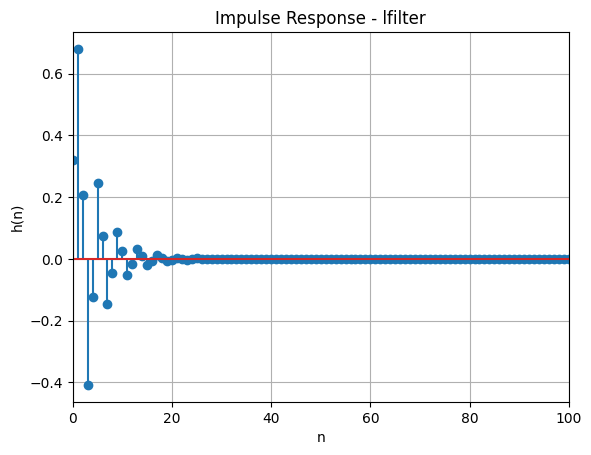

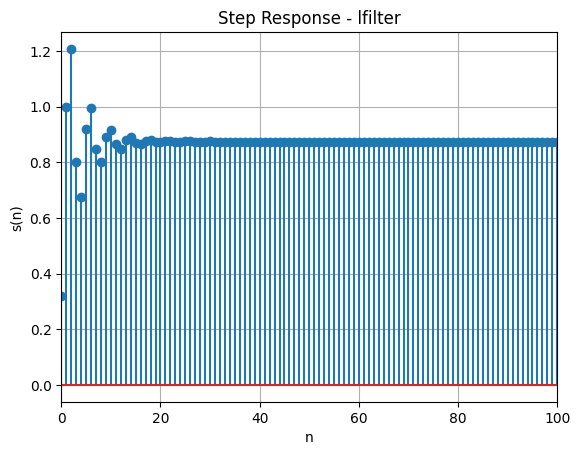

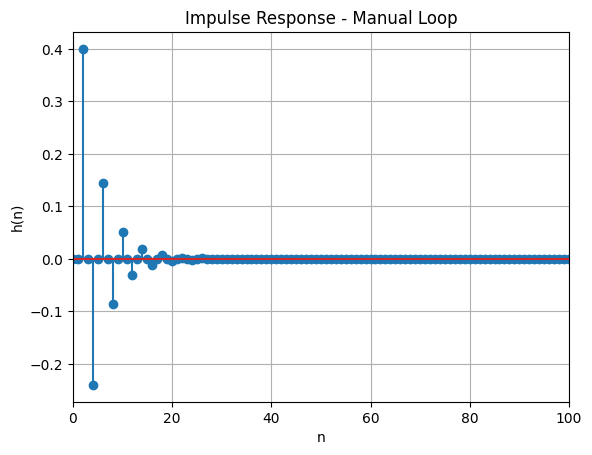

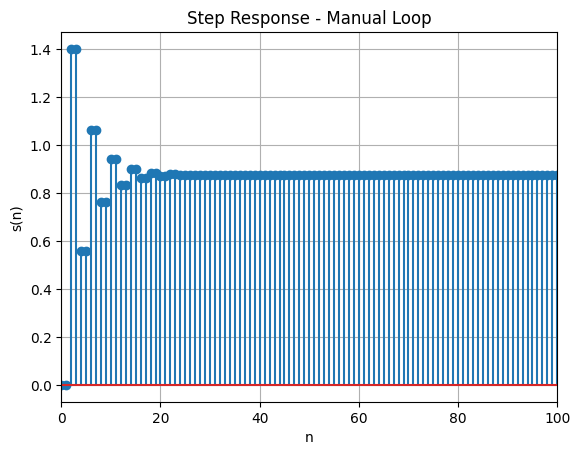

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import signal

delta = lambda n: n == 0
unit = lambda n: 1 if n >= 0 else 0

n = range(0, 101, 1)

b = [0.32, 0.68, 0.4]
a = [1, 0, 0.6]

# ── WAY 1: lfilter (from Lab_02/Lab_03) ─────────────────────────

# Impulse input
x_impulse = np.zeros(101)
for i in range(0, 101, 1):
    x_impulse[i] = int(delta(i))

# Step input
x_step = np.zeros(101)
for i in range(0, 101, 1):
    x_step[i] = unit(i)

h_lfilter = scipy.signal.lfilter(b, a, x_impulse)
s_lfilter = scipy.signal.lfilter(b, a, x_step)

plt.figure()
plt.stem(n, h_lfilter)
plt.title('Impulse Response - lfilter')
plt.xlabel('n')
plt.ylabel('h(n)')
plt.xlim(0, 100)
plt.grid(True)
plt.show()

plt.figure()
plt.stem(n, s_lfilter)
plt.title('Step Response - lfilter')
plt.xlabel('n')
plt.ylabel('s(n)')
plt.xlim(0, 100)
plt.grid(True)
plt.show()

# Impulse response
h_manual = np.zeros(101)
x_impulse2 = np.zeros(101)
for i in range(0, 101, 1):
    x_impulse2[i] = int(delta(i))

for i in range(2, 101, 1):
    h_manual[i] = (0.32 * x_impulse2[i]
                 + 0.68 * x_impulse2[i-1]
                 + 0.4  * x_impulse2[i-2]
                 - 0.6  * h_manual[i-2])

plt.figure()
plt.stem(n, h_manual)
plt.title('Impulse Response - Manual Loop')
plt.xlabel('n')
plt.ylabel('h(n)')
plt.xlim(0, 100)
plt.grid(True)
plt.show()

# Step response
s_manual = np.zeros(101)
x_step2 = np.zeros(101)
for i in range(0, 101, 1):
    x_step2[i] = unit(i)

for i in range(2, 101, 1):
    s_manual[i] = (0.32 * x_step2[i]
                 + 0.68 * x_step2[i-1]
                 + 0.4  * x_step2[i-2]
                 - 0.6  * s_manual[i-2])

plt.figure()
plt.stem(n, s_manual)
plt.title('Step Response - Manual Loop')
plt.xlabel('n')
plt.ylabel('s(n)')
plt.xlim(0, 100)
plt.grid(True)
plt.show()